# <center>🧠 Практика 5. Первая нейросеть и основы PyTorch</center>
### <center>Прикладные технологии ИИ · 120 минут (2 ч.) · Модуль 3</center>

<div style='text-align: center; margin: 20px;'>
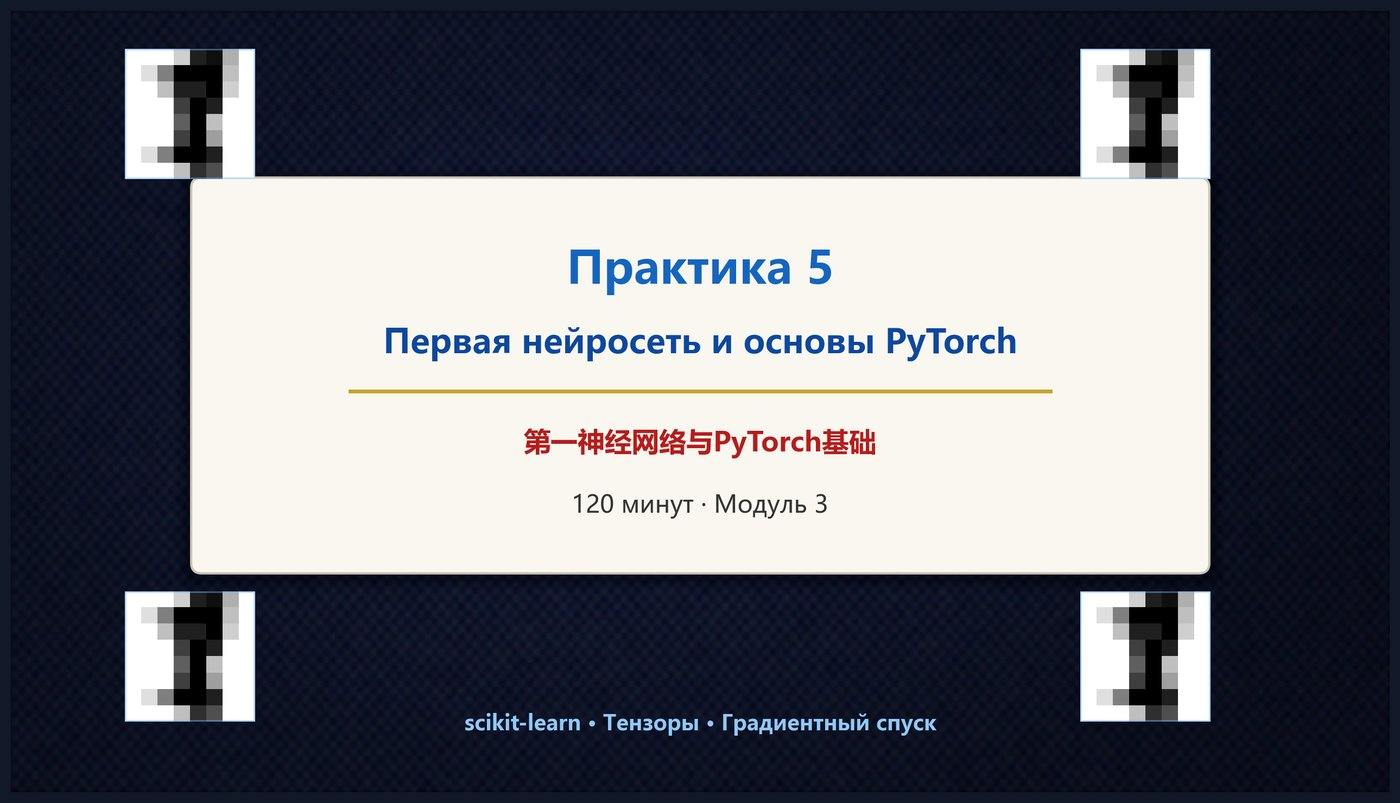
</div>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель:</b> увидеть, что нейросеть — это обучаемая функция, и освоить тензоры и градиентный спуск на простейшем примере.
</div>

<div style='text-align: center; margin: 20px;'>
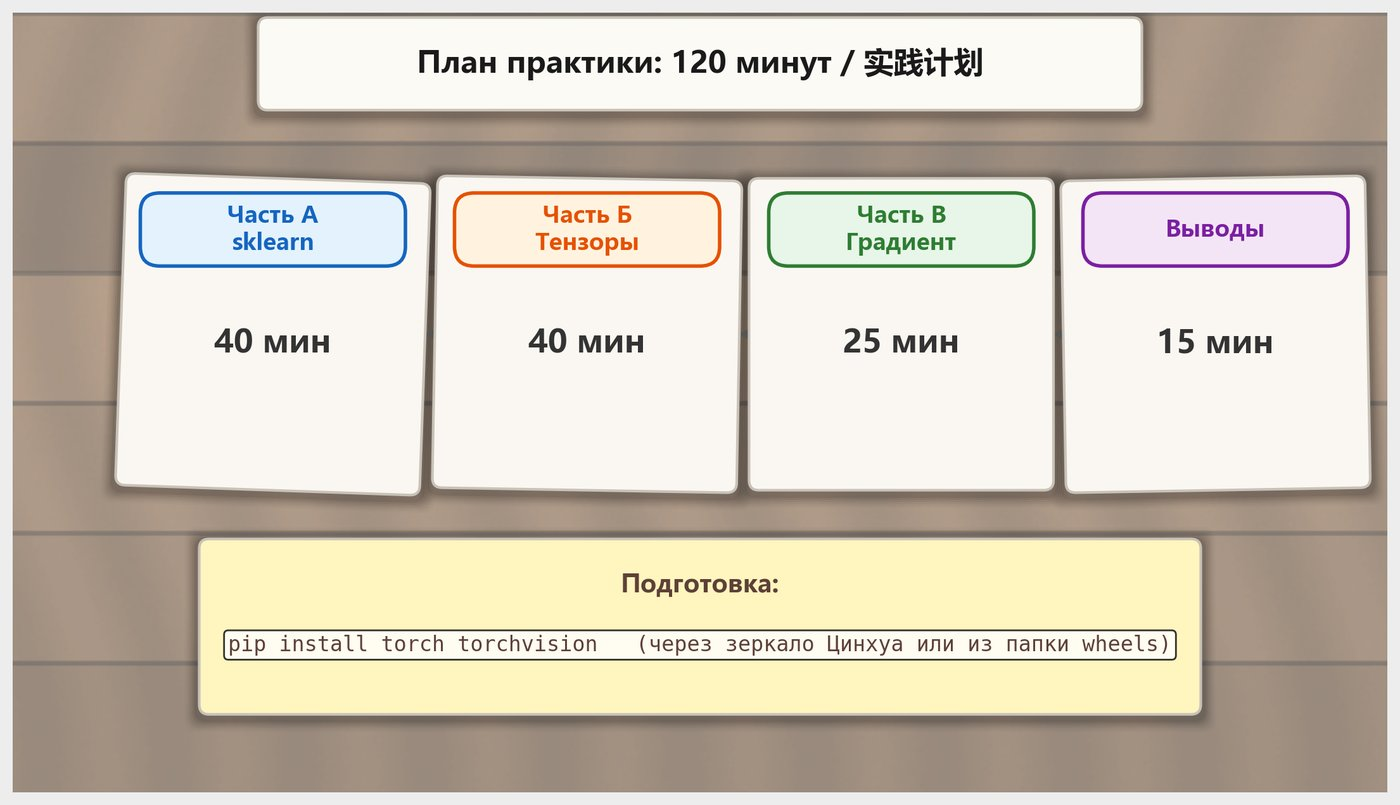
</div>

<center><i>Студент: _______________ · Группа: _______________ · Дата: _______________</i></center>

---
## 📖 Введение: что такое PyTorch

**PyTorch** — это библиотека для глубокого обучения, разработанная компанией Meta AI Research. С момента выхода в 2016 году она стала де-факто стандартом в исследовательском сообществе: по статистике конференций NeurIPS и ICML, более 70 % научных статей по машинному обучению используют именно PyTorch.

### Чем PyTorch отличается от NumPy

NumPy — это библиотека для вычислений с многомерными массивами. PyTorch во многом похож: его основная структура данных — **тензор** (`torch.Tensor`) — это аналог `numpy.ndarray`, и почти все операции знакомы по NumPy (`torch.zeros`, `torch.ones`, `torch.matmul`, broadcasting и т. д.). Но PyTorch добавляет три ключевые возможности, которых в NumPy нет.

1. **Autograd** — автоматическое дифференцирование. Если пометить тензор флагом `requires_grad=True`, PyTorch запоминает все операции в виде вычислительного графа и по вызову `.backward()` автоматически считает градиенты по всем параметрам. В NumPy градиенты нужно выводить и кодить вручную — для многослойной сети это практически невозможно.

2. **GPU-ускорение**. Тензор можно одной строкой перенести на видеокарту: `x = x.to('cuda')`. Все дальнейшие операции выполняются параллельно на сотнях ядер GPU, что даёт ускорение в 10–100 раз для больших матриц. NumPy работает только на CPU.

3. **Динамический вычислительный граф**. В отличие от раннего TensorFlow (статические графы), PyTorch строит граф «на лету» при каждом прямом проходе. Это значит, что внутри модели можно использовать обычные `if`, `while`, циклы Python — структура графа может меняться от батча к батчу. Это критично для рекуррентных сетей с переменной длиной последовательности и для любой модели с условной логикой.

### Зачем PyTorch для глубокого обучения

Нейросеть — это, по сути, **большая дифференцируемая функция** с миллионами параметров. Чтобы её обучить, нужно: вычислить выход (forward pass), измерить ошибку (loss function), посчитать градиенты ошибки по всем параметрам (backward pass) и обновить параметры в сторону уменьшения ошибки (optimizer step). Именно autograd делает PyTorch таким удобным: вручную считать производные для сети из десятков слоёв — это ад. PyTorch делает это автоматически, быстро и на GPU.

<div style='background-color: #E3F2FD; padding: 15px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>💡 В этой практике мы:</b><br>
• Создадим тензоры и увидим, как работает autograd на простом примере;<br>
• Реализуем градиентный спуск вручную и найдём минимум функции;<br>
• Соберём небольшую нейросеть на PyTorch и обучим её распознавать рукописные цифры из набора <code>load_digits</code>.
</div>


In [1]:
# Устранение предупреждения sklearn на Windows/MKL и ConvergenceWarning
import os
os.environ['OMP_NUM_THREADS'] = '1'

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✅ Среда готова')

✅ Среда готова


---
# 🔧 Проверка установки PyTorch

Перед началом работы убедитесь, что PyTorch установлен:

In [2]:
import torch
print('Версия PyTorch:', torch.__version__)
print('CUDA доступна:   ', torch.cuda.is_available())

Версия PyTorch: 2.14.1+cpu
CUDA доступна:    False


Если импорт падает — установите PyTorch через зеркало Цинхуа:
```bash
pip install torch torchvision -i https://pypi.tuna.tsinghua.edu.cn/simple
```
Или из локальной папки `wheels`, если интернет недоступен. На Windows для практики 5 видеокарта не нужна — работаем на CPU.

---
# 🅰️ Часть А. Нейросеть без PyTorch (40 мин)

Мы начнём с **scikit-learn**, чтобы увидеть: нейросеть — это обучаемая функция. Не магия, а математика.

## Набор digits (8×8)

В scikit-learn уже есть набор рукописных цифр — его не нужно скачивать:

<div style='text-align: center; margin: 20px;'>
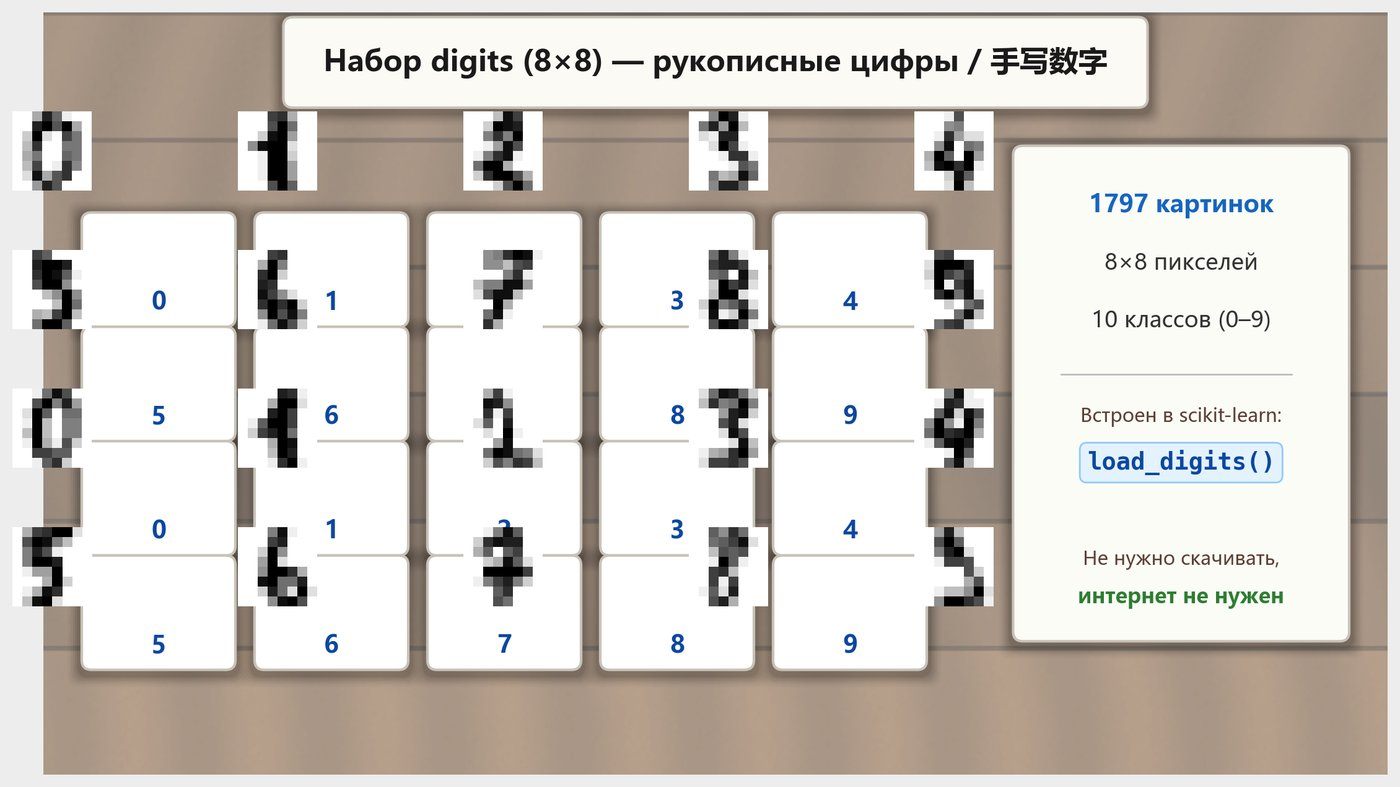
</div>

Форма изображений: (1797, 8, 8)
Форма данных:      (1797, 64)
Метки:             [0 1 2 3 4 5 6 7 8 9]
Первая цифра:


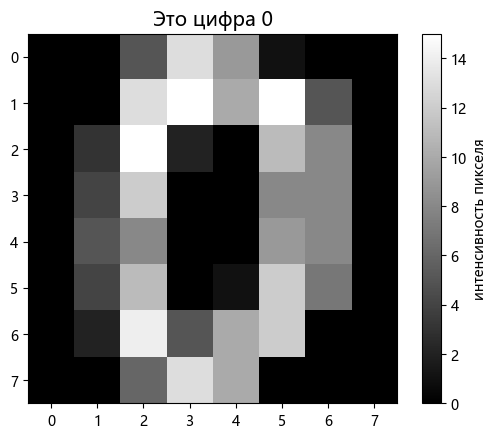

In [3]:
from sklearn.datasets import load_digits

digits = load_digits()
print('Форма изображений:', digits.images.shape)   # (1797, 8, 8)
print('Форма данных:     ', digits.data.shape)     # (1797, 64)
print('Метки:            ', digits.target[:10])    # первые 10 цифр
print('Первая цифра:')
plt.imshow(digits.images[0], cmap='gray')
plt.title(f'Это цифра {digits.target[0]}', fontsize=14)
plt.colorbar(label='интенсивность пикселя')
plt.show()

**Что произошло:**
- каждая цифра — картинка 8×8 пикселей (64 числа);
- в `digits.data` картинки уже развёрнуты в векторы (удобно для нейросети);
- в `digits.target` — правильные ответы (0–9).

## Обучаем первую нейросеть

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=42
)

# Один скрытый слой из 32 нейронов + ранняя остановка
net = MLPClassifier(
    hidden_layer_sizes=(32,),
    max_iter=1000,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42
)
net.fit(X_train, y_train)

print('Точность на тесте:', round(net.score(X_test, y_test), 3))
print('Итераций выполнено:', net.n_iter_)

Точность на тесте: 0.889
Итераций выполнено: 35


**Ожидается точность около 0.95–0.98** (95–98%). Даже маленькая нейросеть справляется с этой задачей.

## Задания для самостоятельной работы

1. Измените `hidden_layer_sizes=(32,)` на `(8,)` — один слой из 8 нейронов. Запишите точность.
2. Измените на `(64, 32)` — два слоя. Запишите точность.
3. Сделайте три запуска в одну таблицу:

| Архитектура | Точность на тесте |
|-------------|-------------------|
| (8,) | |
| (32,) | |
| (64, 32) | |

4. **Вопрос на подумать:** всегда ли больше слоёв = лучше? Где может появиться переобучение?

In [5]:
# Автоматический эксперимент по архитектурам
from sklearn.neural_network import MLPClassifier
import pandas as pd

results = []
for arch in [(8,), (32,), (64, 32), (128, 64, 32)]:
    net = MLPClassifier(
        hidden_layer_sizes=arch,
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=42
    )
    net.fit(X_train, y_train)
    score = round(net.score(X_test, y_test), 3)
    results.append({'Архитектура': str(arch), 'Точность': score, 'Итераций': net.n_iter_})
    print(f'{str(arch):20} | точность = {score} | итераций = {net.n_iter_}')

display(pd.DataFrame(results))

(8,)                 | точность = 0.867 | итераций = 124
(32,)                | точность = 0.889 | итераций = 35
(64, 32)             | точность = 0.924 | итераций = 32
(128, 64, 32)        | точность = 0.965 | итераций = 38


,Архитектура,Точность,Итераций
0,"(8,)",0.867,124
1,"(32,)",0.889,35
2,"(64, 32)",0.924,32
3,"(128, 64, 32)",0.965,38


---
# 🅱️ Часть Б. Тензоры и градиент (40 мин)

Теперь переходим к PyTorch. Он даёт два фундаментальных инструмента:
- **тензоры** — многомерные таблицы чисел, умеющие жить на GPU;
- **autograd** — автоматическое вычисление градиентов.

## Тензоры

Тензор похож на `numpy.ndarray`, но умеет:
- переезжать на GPU одной строкой (`x.to('cuda')`);
- запоминать историю операций и считать производные.

In [6]:
import torch

a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.ones(2, 2)

print('a =\n', a)
print('a + b =\n', a + b)
print('форма:', a.shape, '| dtype:', a.dtype)
print('устройство:', a.device)

a =
 tensor([[1., 2.],
        [3., 4.]])
a + b =
 tensor([[2., 3.],
        [4., 5.]])
форма: torch.Size([2, 2]) | dtype: torch.float32
устройство: cpu


---
## 📦 Тензор — главная структура данных PyTorch

Тензор — это многомерный массив, очень похожий на `numpy.ndarray`, но с тремя суперспособностями: он умеет жить на GPU, запоминать градиенты и участвовать в автоматическом дифференцировании. Именно тензор — «атом», из которого построена любая нейросеть на PyTorch.

<div style='text-align: center; margin: 20px;'>
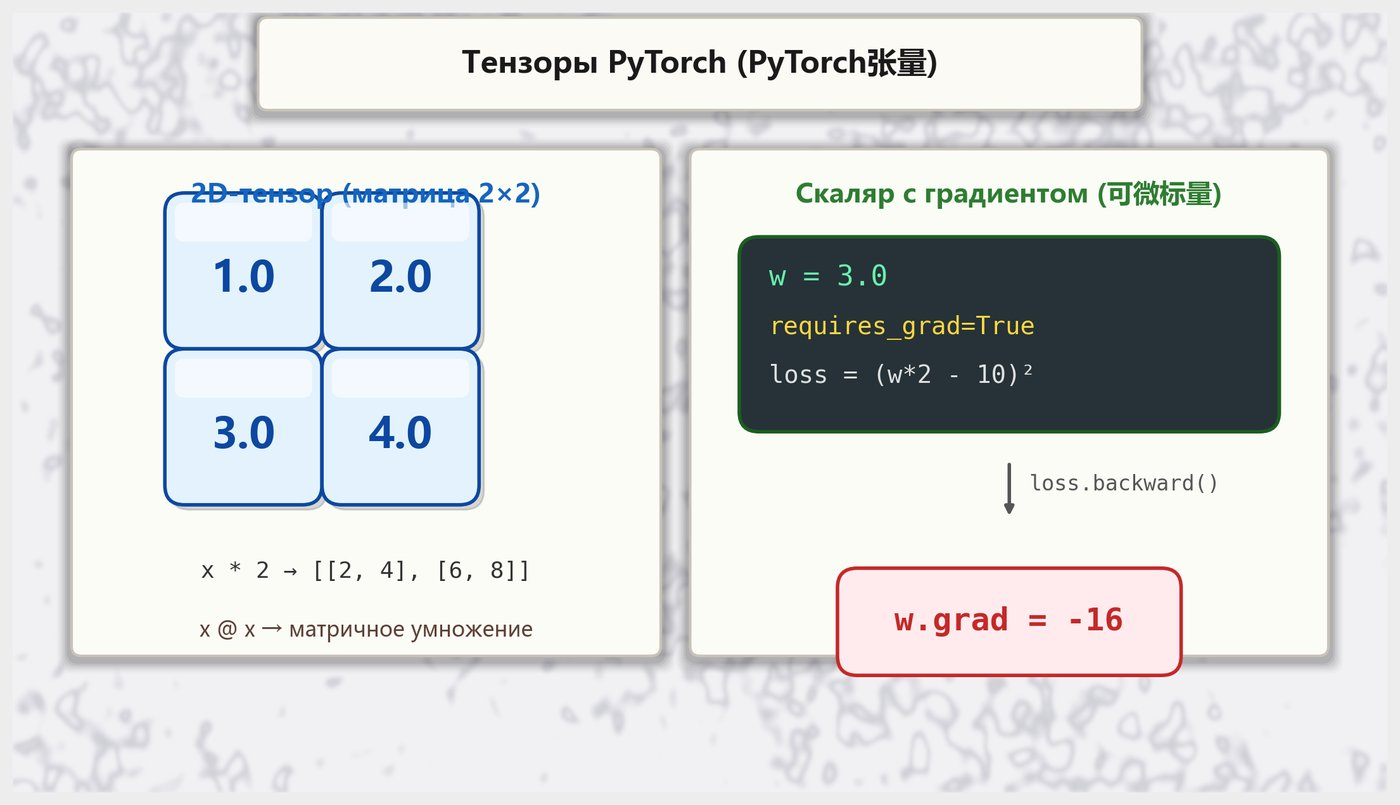
</div>

### Ранг и форма

| Ранг | Что это | Пример |
|---|---|---|
| 0 | скаляр | `torch.tensor(3.14)` |
| 1 | вектор | `torch.tensor([1.0, 2.0, 3.0])` |
| 2 | матрица | `torch.ones(3, 4)` |
| 3 | цветная картинка | `torch.rand(3, 224, 224)` (RGB) |
| 4 | батч картинок | `torch.rand(32, 3, 224, 224)` |

Тип элемента (`dtype`) почти всегда `torch.float32` — это компромисс между точностью и памятью. На GPU двойная точность (`float64`) работает медленнее в 2–4 раза и в реальных задачах почти не используется.

**Совет:** почти любой код на NumPy можно «перенести» в PyTorch заменой `import numpy as np` → `import torch as T` и `np.array` → `torch.tensor`. Синтаксис операций совпадает на 90 %: `+`, `*`, `@`, срезы, broadcasting — всё работает так же. Разница появляется только когда вам нужны градиенты или GPU.


## Autograd: производные бесплатно

Если у тензора поставить `requires_grad=True`, PyTorch запомнит все операции с ним и по вызову `.backward()` посчитает производную.

In [7]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2 + 2 * x + 1     # y = x^2 + 2x + 1
y.backward()
print('y =', y.item())
print('dy/dx в точке x=3:', x.grad.item())   # 2x + 2 = 8

y = 16.0
dy/dx в точке x=3: 8.0


**Проверка вручную:** y = x² + 2x + 1, производная = 2x + 2. При x = 3 получаем 8. Совпало.

## Градиентный спуск на игрушечной функции

Найдём минимум f(x) = (x − 5)². Очевидно, минимум в точке x = 5. Спуск должен туда прийти.

Финальное x: 4.99 (должно быть близко к 5)


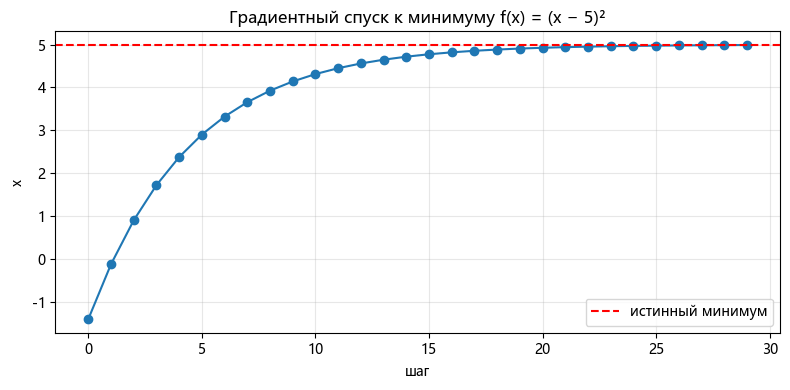

In [8]:
x = torch.tensor(-3.0, requires_grad=True)
lr = 0.1
history = []

for step in range(30):
    loss = (x - 5) ** 2
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad       # шаг в сторону антиградиента
        x.grad.zero_()         # обнуляем градиент для следующего шага
    history.append(x.item())

print('Финальное x:', round(x.item(), 3), '(должно быть близко к 5)')

plt.figure(figsize=(8, 4))
plt.plot(history, marker='o')
plt.axhline(5, color='red', linestyle='--', label='истинный минимум')
plt.xlabel('шаг')
plt.ylabel('x')
plt.title('Градиентный спуск к минимуму f(x) = (x − 5)²')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## 🏔️ Ландшафт потерь и градиентный спуск

Обучение нейросети — это поиск минимума функции потерь (loss) в пространстве миллионов параметров. Эту задачу наглядно изображают как «горный ландшафт»: высота — значение loss, координаты — значения параметров сети. Цель — спуститься в самую низкую точку.

<div style='text-align: center; margin: 20px;'>
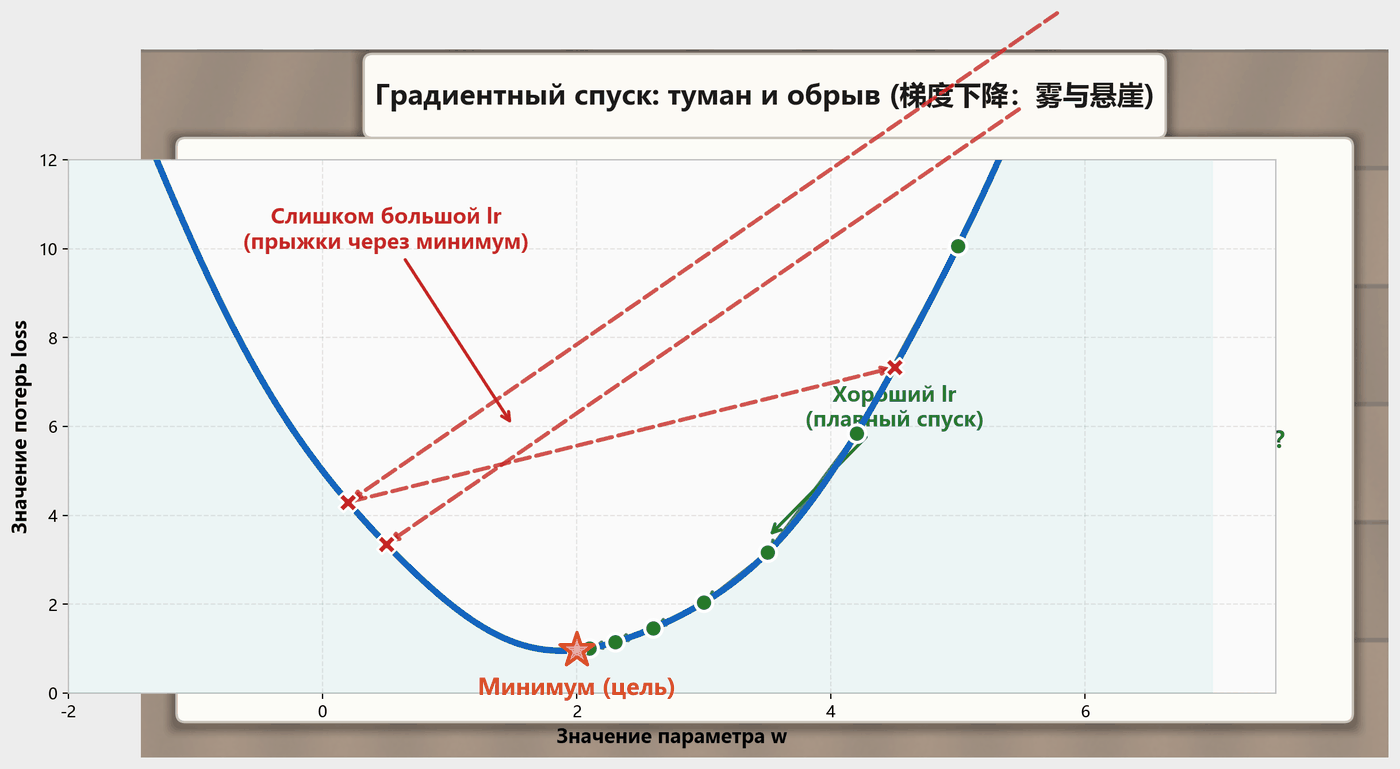
</div>

Градиент функции потерь `∇L` указывает направление **наискорейшего подъёма**. Поэтому, чтобы спуститься, мы двигаемся в **противоположную** сторону: `θ ← θ − lr · ∇L`. Это и есть формула градиентного спуска.

На картинке выше видно, почему градиентный спуск не всегда находит глобальный минимум: есть локальные ямы, седловые точки, длинные плато. В глубоких сетях с миллионами параметров большинство проблем — это именно седловые точки, а не локальные минимумы (на это указывает характерный «плато» в кривой loss во время обучения).

В коде ниже мы решим простейшую задачу: найти минимум `f(x) = (x − 5)²`. Здесь ландшафт — парабола, и спуск сойдётся ровно в `x = 5`. Это позволит увидеть механику autograd и градиентного спуска «под микроскопом».


**Что мы только что сделали:**
1. Поставили `requires_grad=True` — PyTorch запомнил граф операций.
2. Вычислили `loss = (x − 5)²`.
3. `loss.backward()` посчитал `dloss/dx`.
4. Сделали шаг `x -= lr · grad`.
5. Обнулили градиент, чтобы он не накапливался.

Это и есть ядро обучения любой нейросети.

---
# 🅲 Часть В. Полноценная нейросеть на PyTorch (40 мин)

Теперь соберём ту же задачу классификации цифр, но уже на PyTorch:
1. Загрузим данные в тензоры.
2. Опишем модель через `nn.Sequential`.
3. Возьмём `CrossEntropyLoss` и оптимизатор `SGD`.
4. Напишем цикл обучения из пяти шагов.

## Подготовка данных

In [9]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

digits = load_digits()
X = digits.data.astype('float32')
y = digits.target.astype('int64')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_test = scaler.transform(X_test).astype('float32')

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
test_ds  = TensorDataset(torch.from_numpy(X_test),  torch.from_numpy(y_test))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=64)

print('Обучающих батчей:', len(train_loader))
print('Тестовых батчей: ', len(test_loader))

Обучающих батчей: 40
Тестовых батчей:  9


---
## 🔁 Цикл обучения нейросети: 4 шага

Любое обучение глубокой сети сводится к повторению четырёх шагов в каждом батче. Запомните их — на них держится вся индустрия.

### 1. Forward pass (прямой проход)

Прогоняем вход `x` через сеть и получаем предсказание `ŷ = model(x)`. Внутри PyTorch строит вычислительный граф: запоминает, какие тензоры и операции участвуют, чтобы потом по ним посчитать градиенты.

### 2. Loss function (функция потерь)

Сравниваем предсказание `ŷ` с правильным ответом `y` и получаем число — loss. Это скаляр, который показывает «насколько мы ошиблись». Чем меньше — тем лучше.

| Задача | Типичная loss |
|---|---|
| Классификация (метки классов) | `nn.CrossEntropyLoss()` |
| Регрессия (число) | `nn.MSELoss()` |
| Бинарная классификация | `nn.BCEWithLogitsLoss()` |

### 3. Backward pass (обратный проход)

Вызов `loss.backward()` запускает алгоритм обратного распространения ошибки: PyTorch идёт по вычислительному графу **с конца к началу** и для каждого параметра `θ` считает частную производную `∂loss/∂θ`. Эти градиенты копятся в поле `param.grad`.

### 4. Optimizer step (шаг оптимизатора)

Оптимизатор (`SGD`, `Adam`, `RMSprop`) использует накопленные градиенты, чтобы обновить параметры по формуле градиентного спуска: `θ ← θ − lr · ∇loss`. Перед **следующим** батчем нужно обязательно вызвать `optimizer.zero_grad()`, иначе градиенты накопятся за несколько батчей и обучение пойдёт вразнос.

<div style='background-color: #FFF8E1; padding: 15px; border-left: 5px solid #F57F17; margin: 20px 0;'>
<b>🧭 Псевдокод цикла:</b><br>
<code>for epoch in range(N):</code><br>
<code>    for xb, yb in loader:</code><br>
<code>        optimizer.zero_grad()        # 0. обнулить градиенты</code><br>
<code>        y_hat = model(xb)            # 1. forward</code><br>
<code>        loss = loss_fn(y_hat, yb)    # 2. loss</code><br>
<code>        loss.backward()              # 3. backward</code><br>
<code>        optimizer.step()             # 4. step</code>
</div>

В коде ниже именно этот цикл применён к классификации цифр из `load_digits`: сеть из двух слоёв `Linear` с `ReLU`, 10 эпох, оптимизатор `SGD` с `lr=0.1`.


## Модель и цикл обучения

In [10]:
import torch.nn as nn
from torch.optim import SGD

model = nn.Sequential(
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = SGD(model.parameters(), lr=0.1)

for epoch in range(10):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
    print(f'эпоха {epoch+1:2d} | loss = {loss.item():.4f}')

эпоха  1 | loss = 1.0753
эпоха  2 | loss = 0.5136
эпоха  3 | loss = 0.2108
эпоха  4 | loss = 0.2632
эпоха  5 | loss = 0.1943
эпоха  6 | loss = 0.2819
эпоха  7 | loss = 0.0291
эпоха  8 | loss = 0.0500
эпоха  9 | loss = 0.0110
эпоха 10 | loss = 0.1176


## Проверка точности

In [11]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for xb, yb in test_loader:
        preds = model(xb).argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += yb.size(0)

print(f'Точность на тесте: {correct / total:.3f}')

Точность на тесте: 0.963


---
## 🎚️ Learning rate — главный гиперпараметр

**Learning rate (lr, скорость обучения)** — это размер шага, который делает оптимизатор на каждой итерации. Формула обновления: `θ ← θ − lr · ∇loss`. От выбора lr зависит **всё**: слишком большой — обучение разойдётся, слишком маленький — будет ползти часами и не дойдёт до минимума.

<div style='text-align: center; margin: 20px;'>
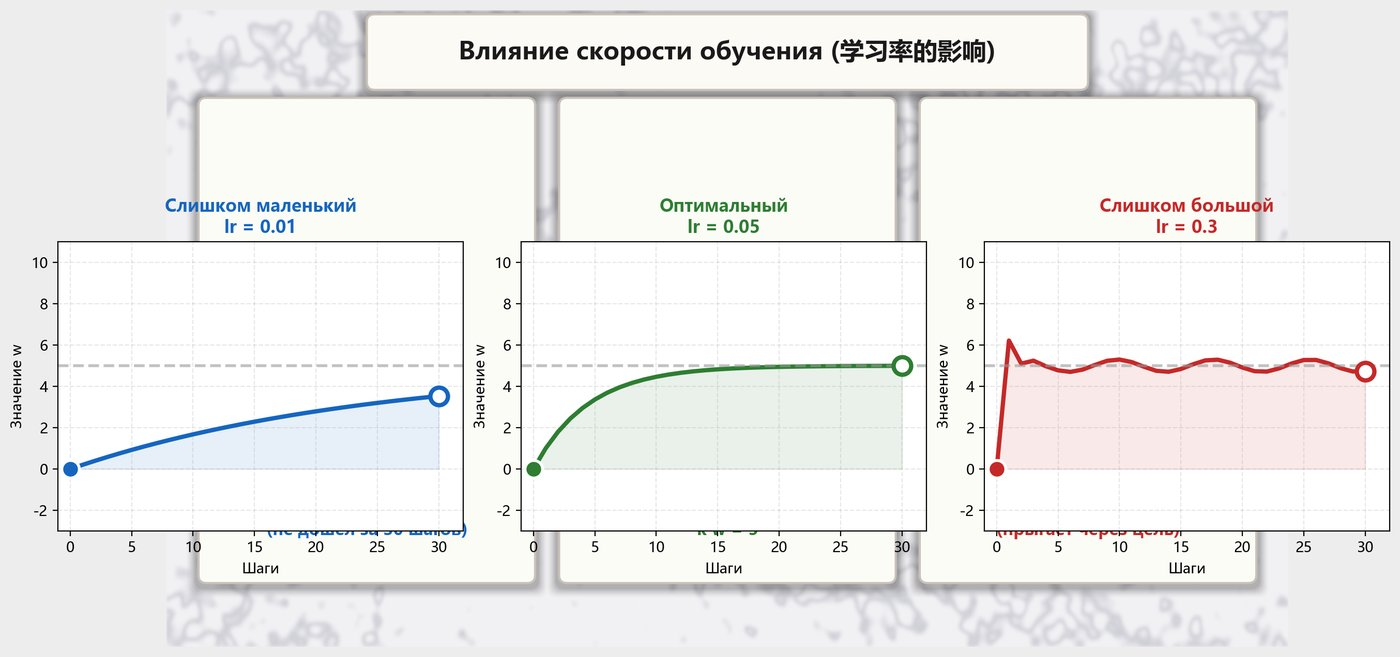
</div>

### Три сценария

| lr | Что происходит | Как это выглядит на графике loss |
|---|---|---|
| **Слишком большой** (≥ 1.0 для SGD) | Шаги слишком широкие, алгоритм «перепрыгивает» минимум, loss растёт или осциллирует | loss скачет вверх-вниз, иногда уходит в NaN |
| **Слишком маленький** (≤ 0.0001 для SGD) | Шаги крошечные, сеть едва двигается | loss уменьшается, но очень медленно — за 10 эпох почти не меняется |
| **Нормальный** (0.01–0.1 для SGD, 0.0001–0.001 для Adam) | Плавный спуск к минимуму | loss падает монотонно, иногда с лёгкими колебаниями |

### Практический совет

Стартуйте с `lr=0.01` для SGD или `lr=0.001` для Adam — это «безопасные» значения, которые работают в 80 % задач. Если loss:
- **не уменьшается** → увеличьте lr в 3–10 раз;
- **скачет или уходит в NaN** → уменьшите lr в 3–10 раз;
- **падает слишком медленно** → попробуйте адаптивный оптимизатор (Adam) или lr warmup (постепенный рост lr в первые эпохи).

В заданиях ниже вы попробуете три значения `lr` (0.001, 0.01, 0.1, 1.0) и увидите эту разницу на собственном опыте.


**Ожидается 0.95–0.98** — как и у scikit-learn, только теперь мы сами написали цикл обучения и увидели, как считаются градиенты.

## Задания для самостоятельной работы

1. Замените `nn.Linear(64, 32)` на `nn.Linear(64, 8)`. Как изменилась точность?
2. Добавьте второй скрытый слой `nn.Linear(32, 16), nn.ReLU()`. Что произошло?
3. Измените `lr` с 0.1 на 0.01 и на 1.0. Запишите, как меняется loss по эпохам.
4. **Вопрос на подумать:** почему `optimizer.zero_grad()` стоит вызывать именно перед `loss.backward()`, а не после?

---
# 📝 Ожидаемый результат

К концу практики у вас должно быть:
- [x] таблица точностей для разных архитектур (scikit-learn);
- [x] график градиентного спуска для f(x) = (x − 5)²;
- [x] обученная модель на PyTorch с точностью 0.95+;
- [x] короткий вывод: чем scikit-learn удобен, а зачем нужен PyTorch.

## Вопросы для устной защиты

1. Что такое тензор и чем он отличается от массива NumPy?
2. Что делает `requires_grad=True` и зачем нужен `.backward()`?
3. Перечислите пять шагов цикла обучения.
4. Почему градиенты нужно обнулять перед каждым шагом?
5. Чем `CrossEntropyLoss` отличается от `MSELoss` и когда что использовать?
6. Почему архитектура `(128, 64, 32)` не обязательно даст точность выше, чем `(32,)`?

---
# 🆘 Типичные ошибки

| Ошибка | Причина | Решение |
|--------|---------|--------|
| `ModuleNotFoundError: No module named 'torch'` | PyTorch не установлен | `pip install torch torchvision -i https://pypi.tuna.tsinghua.edu.cn/simple` |
| `RuntimeError: grad can be implicitly created only for scalar outputs` | Вызвали `.backward()` у не-скаляра | Приведите loss к одному числу (`.mean()`/`.sum()`) |
| `RuntimeError: expected scalar type Float but found Double` | Разные dtype | Приводите входы к `float32` (`X.astype('float32')`) |
| Loss не уменьшается | Слишком большой `lr` или забыли `optimizer.zero_grad()` | Уменьшите `lr`, проверьте порядок шагов |
| Точность внезапно падает до 0.1 | Неправильные метки (например, one-hot вместо индексов) | `CrossEntropyLoss` ждёт целые индексы классов |
| Warning про KMeans/MKL | Это не про PyTorch | Добавьте `os.environ['OMP_NUM_THREADS']='1'` в начало |

---
# 📚 Словарь терминов

| Русский | 中文 | English |
|---------|------|---------|
| Тензор | 张量 | Tensor |
| Градиент | 梯度 | Gradient |
| Автоматическое дифференцирование | 自动微分 | Autograd |
| Функция потерь | 损失函数 | Loss function |
| Оптимизатор | 优化器 | Optimizer |
| Скорость обучения | 学习率 | Learning rate |
| Эпоха | 轮次 | Epoch |
| Батч | 批次 | Batch |
| Переобучение | 过拟合 | Overfitting |
| Нейросеть | 神经网络 | Neural network |

---
## 🏠 Домашнее задание

1. Повторите эксперимент с архитектурами на PyTorch: `(8,)`, `(32,)`, `(64, 32)`. Сравните с результатами scikit-learn.
2. Постройте график loss по эпохам для трёх значений `lr`: 0.001, 0.01, 0.1. Опишите, как меняется сходимость.
3. Объясните своими словами (5–6 предложений), зачем нужен PyTorch, если scikit-learn уже умеет обучать нейросети.

<center><i>Преподаватель: _______________ · Оценка: _____ / 100</i></center>

---
## 🎓 Итоги практики

В этой практике мы прошли путь от «магии нейросетей» к осознанному коду. Что мы узнали:

1. **Нейросеть — это обучаемая функция.** scikit-learn показал, что классификация цифр работает «из коробки» за пару строк, и точность 95 %+ достигается даже маленькой сеткой `(32,)` или `(64, 32)`.

2. **Тензор — основа PyTorch.** Он похож на массив NumPy, но умеет жить на GPU и хранить градиенты. Почти весь код на NumPy переносится в PyTorch заменой импорта и `np.array` → `torch.tensor`.

3. **Autograd — бесплатно считает производные.** Пометив `requires_grad=True`, мы получаем градиент любой функции по любому параметру одной строкой `.backward()`. Вручную выводить производные для многослойной сети — безнадёжно.

4. **Цикл обучения = 4 шага:** forward → loss → backward → optimizer step. Это ядро любой современной системы глубокого обучения — от PyTorch до TensorFlow и JAX.

5. **Learning rate критичен.** Слишком большой — расходимся, слишком маленький — ползём. Начинать стоит с `lr=0.01` для SGD или `0.001` для Adam, и тюнить под задачу по поведению кривой loss.

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>✅ Что попробовать дальше:</b><br>
• Сверточные сети (CNN) для картинок — <code>nn.Conv2d</code>;<br>
• Transfer learning — взять предобученную ResNet и дообучить под свой датасет;<br>
• Градиентный спуск на реальной задаче регрессии с MSE вместо классификации с CrossEntropy.
</div>
